In [3]:
import pandas as pd
import seaborn as sb
import numpy as np

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

ss = StandardScaler()
pca = PCA()

df = pd.read_excel('Dry_Bean_Dataset.xlsx')
x = df.iloc[:,:-1]

---------KMeans---------

KMeans with normalization

In [4]:
# Kmeans Train the dataset on the data an output the groups

x_kmeans = ss.fit_transform(x)
SS_total = np.sum(((x_kmeans - x_kmeans.mean(axis=0)) ** 2))
km = KMeans(n_clusters=7, random_state=41, n_init=10)
labels = km.fit_predict(x_kmeans)

df_k = pd.DataFrame(
    data=[
        df.iloc[:,0],
        labels
    ],
    index=["Sample_id","Group"],
).transpose()


In [5]:
df_k['Group'].value_counts() # num in each group

# explained_variance
SS_in = km.inertia_

Metrics, visualization and traits

In [6]:
df_k # model results
silhouette_score(x_kmeans, df_k['Group']) # .259
explained_variance = 1 - SS_in / SS_total # 73.028%

<Axes: xlabel='PC1', ylabel='PC2'>

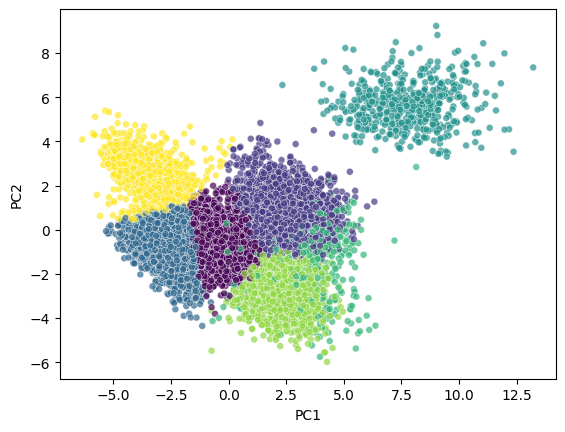

In [7]:
pca_2d = PCA(n_components=2)

x_kmeans_2d = pca_2d.fit_transform(x_kmeans)

# Create visualization dataframe
df_kmeans_viz = pd.DataFrame({
    'PC1': x_kmeans_2d[:, 0],
    'PC2': x_kmeans_2d[:, 1],
    'Group': labels
})

# Plot

sb.scatterplot(
    data=df_kmeans_viz,
    x='PC1',
    y='PC2',
    hue='Group',
    palette='viridis',
    s=25,
    alpha=0.7,
    legend=False
)

In [8]:
df_cluster_analysis = df.copy()
df_cluster_analysis['Cluster'] = df_k['Group']
df_cluster_analysis.head()
df_cluster_analysis.groupby('Cluster')[df_cluster_analysis.columns].mean()

,sample_id,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4,Class,Cluster
Cluster,,,,,,,,,,,,,,,,,,,
0,6520.897894,44371.475750,793.465948,298.004179,189.913594,1.571591,0.768396,44908.111678,237.296043,0.747665,0.988031,0.883464,0.796914,0.006761,0.001684,0.635570,0.995740,NaN,0.0
1,6845.981459,74016.612253,1060.479746,394.194882,240.078283,1.645949,0.787751,75133.622733,306.381791,0.757130,0.985067,0.825363,0.779144,0.005362,0.001226,0.608239,0.993745,NaN,1.0
2,7020.859599,31518.666985,657.823485,243.104599,164.884865,1.477147,0.732387,31887.847819,199.840674,0.756178,0.988329,0.911193,0.822500,0.007792,0.002202,0.677013,0.997032,NaN,2.0
3,6787.250000,173667.573077,1586.450225,593.525661,374.527144,1.585856,0.770630,175992.065385,469.206095,0.776630,0.986943,0.864496,0.792556,0.003440,0.000844,0.629088,0.991874,NaN,3.0
4,6942.095941,65239.343173,1003.919982,385.922539,216.945523,1.785250,0.823290,67003.071956,286.413734,0.729917,0.973356,0.803879,0.743528,0.006072,0.001151,0.553920,0.981417,NaN,4.0
5,6850.978495,53677.334465,919.905800,373.709763,183.367682,2.040578,0.870050,54381.967176,260.820022,0.702960,0.986966,0.794545,0.698708,0.007024,0.001036,0.488622,0.993586,NaN,5.0
6,6794.129812,39402.732478,721.971750,248.651677,201.397149,1.235375,0.579028,39785.897335,223.517338,0.773073,0.990367,0.946931,0.899877,0.006358,0.002579,0.810339,0.998335,NaN,6.0


Kmeans with pca

In [9]:
# Kmeans Train the dataset on the data an output the groups
x_kmeans_pca = ss.fit_transform(x)
pca_1 = pca.fit(x_kmeans_pca)
x_kmeans_pca = pca_1.fit_transform(x_kmeans_pca) # pca_1.explained_variance_

km2 = KMeans(n_clusters=7, random_state=41, n_init=10)
labels_2 = km2.fit_predict(x_kmeans_pca[:,:-9])


df_k_means_pca = pd.DataFrame(
    data=[
        df.iloc[:,0],
        labels_2
    ],
    index=["Sample_id","Group"],
).transpose()

SS_in2 = km2.inertia_

# labels_2 #resulting classifications
# df_k_means_pca #labels

Metrics, visualization, and traits

In [11]:
explained_variance = 1 - SS_in2 / SS_total # 73.325%

silhouette_score(x_kmeans_pca, df_k_means_pca['Group']) # .2595

df_k_means_pca['Group'].value_counts() #Num Values in each group

Group
1    3143
4    3132
0    2482
3    2025
6    1770
2     539
5     520
Name: count, dtype: int64

<Axes: xlabel='PC1', ylabel='PC2'>

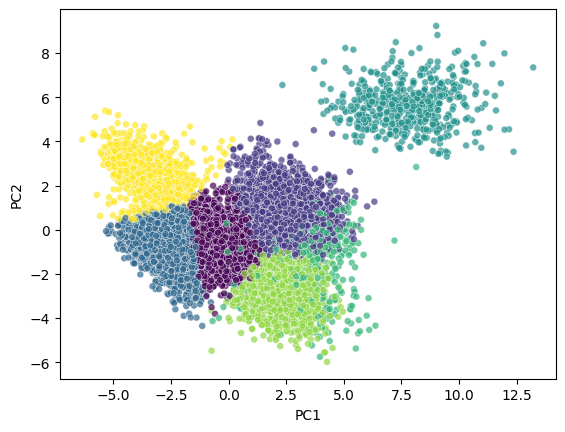

In [12]:
x_kmeans_2d_pca = pca_2d.fit_transform(df_k_means_pca)

df_kmeans_viz_2 = pd.DataFrame({
    'PC1': x_kmeans_2d_pca[:, 0],
    'PC2': x_kmeans_2d_pca[:, 1],
    'Group': labels
})

# Plot

sb.scatterplot(
    data=df_kmeans_viz,
    x='PC1',
    y='PC2',
    hue='Group',
    palette='viridis',
    s=25,
    alpha=0.7,
    legend=False
)

In [13]:
df_cluster_analysis_2 = df.copy()
df_cluster_analysis_2['Cluster'] = df_k_means_pca['Group']
df_cluster_analysis_2.head()
df_cluster_analysis_2.groupby('Cluster')[df_cluster_analysis_2.columns].mean()

,sample_id,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4,Class,Cluster
Cluster,,,,,,,,,,,,,,,,,,,
0,6849.748187,74020.215149,1060.434236,394.190050,240.094021,1.645803,0.787706,75137.678888,306.389065,0.757122,0.985062,0.825462,0.779177,0.005361,0.001227,0.608292,0.993740,NaN,0.0
1,7023.338212,31522.355393,657.862824,243.114711,164.896922,1.477104,0.732365,31891.642380,199.852149,0.756193,0.988327,0.911189,0.822513,0.007791,0.002202,0.677034,0.997033,NaN,1.0
2,6938.890538,65201.591837,1003.718640,385.819319,216.878068,1.785350,0.823283,66967.671614,286.326143,0.730123,0.973307,0.803718,0.743510,0.006074,0.001151,0.553899,0.981396,NaN,2.0
3,6792.653333,39404.856296,721.985501,248.654445,201.405594,1.235334,0.578992,39787.924444,223.523318,0.773081,0.990370,0.946946,0.899892,0.006358,0.002579,0.810366,0.998336,NaN,3.0
4,6516.894955,44368.399106,793.437183,298.003089,189.902325,1.571669,0.768425,44904.880587,237.288544,0.747654,0.988033,0.883471,0.796893,0.006761,0.001684,0.635536,0.995739,NaN,4.0
5,6787.250000,173667.573077,1586.450225,593.525661,374.527144,1.585856,0.770630,175992.065385,469.206095,0.776630,0.986943,0.864496,0.792556,0.003440,0.000844,0.629088,0.991874,NaN,5.0
6,6850.603955,53694.806780,920.100658,373.729284,183.418361,2.040181,0.869987,54399.853107,260.861431,0.702936,0.986964,0.794485,0.698779,0.007023,0.001036,0.488723,0.993581,NaN,6.0


Model selection

In [14]:
df_k_means_pca

,Sample_id,Group
0,1,4
1,2,3
2,3,0
3,4,4
4,5,1
...,...,...
13606,13607,4
13607,13608,1
13608,13609,0
13609,13610,1
